# Liaisons hydrogène et géométrie du squelette protéique

Ce carnet ouvre le pli **Structures** de la série **Bio & Médecine**. Il ne replie pas encore une protéine : il établit ce qu'est géométriquement une **liaison hydrogène** dans le squelette, et ce que la carte des couples d'angles dièdres contient comme familles d'hélices régulières. C'est le socle dont les feuilles suivantes se serviront pour parler de repliement.

Le point de départ est un fait de Penner : dans une protéine, les liaisons hydrogène qui referment le squelette ne sont pas des liens quelconques. Chacune peut se lire comme un **élément du groupe des rotations de l'espace**, et la statistique de ces éléments sur les structures déposées prend la forme d'une distribution sur $SO(3)$ dont le mode est le tour interne de l'hélice $\alpha$ idéale.

Le carnet applique à cette question le contrat de méthode de la série :

1. **Modèle** — il énonce la géométrie du squelette et les paramètres qu'il déclare.
2. **Calcul** — il construit les chaînes, mesure les vis, balaie la carte des angles.
3. **Contrôle indépendant** — il compare chaque mesure à une voie qui ne partage pas son code : formule analytique de la vis, régularité translationnelle, aller-retour des dièdres.
4. **Contre-témoin** — il construit les cas où le contrôle doit échouer : hélices de sens opposé, conformation étendue, liaison peptidique tordue.
5. **Statut** — il sépare ce qui est mesuré ici, ce qui est cité de Penner, et ce qui reste ouvert.

Aucune structure expérimentale n'est lue : tout ce qui suit vient de chaînes synthétiques construites à partir d'un modèle déclaré.

## Ce que ce carnet établit, et ce qu'il n'établit pas

| Section | Question | Contrôle indépendant | Contre-témoin |
|---|---|---|---|
| 1 | Le modèle redonne-t-il ses propres angles, et une chaîne à angles constants est-elle régulière ? | Aller-retour des dièdres sur les coordonnées, plus la régularité translationnelle | Une hélice de sens opposé doit sortir avec les signes opposés |
| 2 | Le critère à quatre conditions retrouve-t-il le tour de l'hélice $\alpha$ ? | Distances et angles comparés aux seuils de DSSP | L'affectation inverse, donneur et accepteur échangés, doit échouer |
| 3 | La carte des couples $(\varphi,\psi)$ fait-elle un point ou un bassin ? | Paramètres hélicoïdaux recalculés pour chaque case retenue | Les deux conditions d'angle doivent retirer des cases que les distances seules acceptent |
| 4 | La rotation du groupe peptidique est-elle la vis de l'hélice ? | Angle et axes mesurés contre la formule analytique | Le miroir doit avoir le même angle de rotation et le pas de vis opposé |

**Ce que la feuille apporte au pli** : le vocabulaire géométrique et les instruments de mesure qui rendent les feuilles suivantes vérifiables. Sans eux, un repliement calculé ne se distingue pas d'une chaîne quelconque, et rien ne dit si une conformation trouvée par un algorithme est une hélice, un feuillet, ou du bruit.

Ce carnet **n'établit pas** pourquoi l'hélice $\alpha$ est droite. Il établit que le modèle employé ne peut pas le dire, et il le montre par un contre-témoin plutôt que de le passer sous silence.

## Outils et conventions

Le carnet n'utilise que la bibliothèque scientifique standard : `numpy` pour les tableaux, `scipy.ndimage.label` pour compter les régions connexes d'une carte, `matplotlib` pour les figures.

**Paramètres déclarés.** Les longueurs de liaison et les angles de valence ne sont pas mesurés ici et ne sont pas tirés de Penner : ce sont des valeurs **déclarées**, choisies comme représentatives d'un squelette peptidique et écrites en tête du premier bloc de code. Le couple $(\varphi,\psi)$ de référence, $(-57°,-47°)$, l'est aussi. Un résultat du carnet se lit donc **relativement à ce jeu de paramètres** ; la section 4 en mesure la sensibilité sur l'angle $N-C_\alpha-C$.

**Convention de signe.** Un dièdre est calculé par

$$\theta = \operatorname{atan2}\big((n_1\times n_2)\cdot \hat b_2,\ n_1\cdot n_2\big),\qquad n_1 = b_1\times b_2,\quad n_2 = b_2\times b_3$$

ce qui donne un dièdre **positif sur une hélice droite**. Le carnet ne suppose pas cette convention : il la vérifie sur deux hélices explicites avant toute mesure.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.ndimage

plt.rcParams.update({
    'figure.figsize': (7.5, 4.2),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 10,
})

print(f'numpy {np.__version__} | scipy {scipy.__version__}')

numpy 2.4.6 | scipy 1.18.1


## 1. Le squelette comme modèle géométrique

### Ce que dit Penner

Le squelette d'une protéine est une suite répétée d'atomes

$$\cdots - C_\alpha - C = N - C_\alpha - \cdots$$

Le **groupe peptidique** réunit quatre atomes consécutifs du squelette et deux atomes latéraux, l'oxygène du carbonyle et l'hydrogène de l'azote. Ces **six atomes sont coplanaires** : le carbone et l'azote du groupe sont hybridés $sp^2$, les angles en $C$ et en $N$ valent à peu près $120°$, et c'est le carbone $\alpha$, $sp^3$, qui porte la géométrie tétraédrique. Deux angles dièdres par résidu suffisent alors à décrire la conformation du squelette — $\varphi_i$ autour de la liaison $N_i-C_{\alpha i}$ et $\psi_i$ autour de $C_{\alpha i}-C_i$ — à une exception près : le premier $\varphi$ et le dernier $\psi$ n'existent pas, faute de voisin.

Penner ne donne pas de valeurs numériques pour les couples $(\varphi,\psi)$ : son propos porte sur la statistique des liaisons hydrogène, pas sur les régions autorisées de la carte. Le carnet doit donc déclarer lui-même un point de référence, et il le fait.

### Le modèle du carnet

La chaîne est construite atome par atome à partir de longueurs et d'angles de valence fixés, en plaçant chaque atome par rapport aux trois précédents. La torsion $\omega$ de la liaison peptidique vaut $180°$ par défaut — trans planaire — et la sensibilité à cette valeur est mesurée plus bas.

In [2]:
RAD = np.pi / 180.0

# Longueurs de liaison et angles de valence DECLARES : ni mesures ici, ni issus de Penner.
L_N_CA = 1.458
L_CA_C = 1.525
L_C_N = 1.329
L_C_O = 1.231
L_N_H = 1.010
A_N_CA_C = 109.47
A_CA_C_N = 120.0
A_C_N_CA = 120.0

# Point de reference alpha : couple (phi, psi) DECLARE lui aussi, ni mesure ni cite.
ALPHA = (-57.0, -47.0)

def vecteur_unitaire(v):
    '''Vecteur de meme direction et de norme 1.'''
    return v / np.linalg.norm(v)

def placer(a, b, c, longueur, angle_deg, diedre_deg):
    '''Place d tel que |cd| = longueur, l'angle (b, c, d) valant angle_deg et le diedre a-b-c-d diedre_deg.'''
    # Base (bc, m, n) : (bc, m) est le plan des trois atomes connus, n sa normale.
    # Le diedre est une rotation autour de bc, nulle lorsque d reste dans ce plan.
    bc = vecteur_unitaire(c - b)
    n = vecteur_unitaire(np.cross(b - a, bc))
    m = np.cross(n, bc)
    theta, phi = angle_deg * RAD, diedre_deg * RAD
    return c + longueur * (-np.cos(theta) * bc + np.sin(theta) * (np.cos(phi) * m + np.sin(phi) * n))

def dihedre(p1, p2, p3, p4):
    '''Diedre p1-p2-p3-p4 en degres dans (-180, 180], positif pour une helice droite.'''
    # Le signe est celui du produit mixte (n1 x n2) . b2 : c'est la convention
    # verifiee sur les deux helices explicites du premier controle.
    b1, b2, b3 = p2 - p1, p3 - p2, p4 - p3
    n1, n2 = np.cross(b1, b2), np.cross(b2, b3)
    return np.degrees(np.arctan2(np.dot(np.cross(n1, n2), vecteur_unitaire(b2)), np.dot(n1, n2)))

def angle(p1, p2, p3):
    '''Angle en degres au sommet p2.'''
    u = vecteur_unitaire(p1 - p2)
    v = vecteur_unitaire(p3 - p2)
    return np.degrees(np.arccos(np.clip(np.dot(u, v), -1.0, 1.0)))

def ecart_angulaire(x, y):
    '''Ecart signe entre deux angles en degres, ramene dans (-180, 180].'''
    # Soustraction circulaire : deux angles a -179 et 179 deg sont distants de 2 deg,
    # mais leur difference brute vaut 358 ; le modulo ramene le resultat dans (-180, 180].
    return (x - y + 180.0) % 360.0 - 180.0

In [3]:
def construire_chaine(phis, psis, omegas=None, angle_ncac=A_N_CA_C):
    '''Construit une chaine a partir des couples (phi, psi) ; omega planar trans par defaut.

    phis[0] et psis[-1] ne sont pas utilises : le premier phi et le dernier psi
    n'existent pas, faute de residu voisin. L'oxygene du dernier residu et
    l'hydrogene du premier valent NaN et ne sont jamais lus.
    '''
    n = len(phis)
    # 180 deg par defaut : groupe peptidique plan, configuration trans ; le contre-temoin
    # de la liaison tordue ecarte cette valeur pour en montrer le prix.
    if omegas is None:
        omegas = np.full(n - 1, 180.0)
    N = np.zeros((n, 3))
    CA = np.zeros((n, 3))
    C = np.zeros((n, 3))
    O = np.full((n, 3), np.nan)
    H = np.full((n, 3), np.nan)
    # Les trois premiers atomes sont poses a la main, dans un repere arbitraire :
    # tout le reste en derive, et aucune mesure ne depend donc d'un repere absolu.
    N[0] = [0.0, 0.0, 0.0]
    CA[0] = [L_N_CA, 0.0, 0.0]
    C[0] = placer(N[0] + np.array([0.0, 1.0, 0.0]), N[0], CA[0], L_CA_C, angle_ncac, 0.0)
    for i in range(1, n):
        N[i] = placer(N[i - 1], CA[i - 1], C[i - 1], L_C_N, A_CA_C_N, psis[i - 1])
        CA[i] = placer(CA[i - 1], C[i - 1], N[i], L_N_CA, A_C_N_CA, omegas[i - 1])
        C[i] = placer(C[i - 1], N[i], CA[i], L_CA_C, angle_ncac, phis[i])
    # O et H sont places en bissectrice exterieure du groupe peptidique : c'est la
    # seule position que fixe le modele, leurs longueurs etant declarees.
    for i in range(n - 1):
        O[i] = C[i] + L_C_O * -vecteur_unitaire(vecteur_unitaire(CA[i] - C[i]) + vecteur_unitaire(N[i + 1] - C[i]))
    for i in range(1, n):
        H[i] = N[i] + L_N_H * -vecteur_unitaire(vecteur_unitaire(CA[i] - N[i]) + vecteur_unitaire(C[i - 1] - N[i]))
    return {'N': N, 'CA': CA, 'C': C, 'O': O, 'H': H}

def planarite(chaine):
    '''Ecart quadratique moyen des six atomes du groupe peptidique a leur meilleur plan.'''
    n = len(chaine['N'])
    ecarts = []
    for i in range(n - 1):
        pts = np.array([chaine['CA'][i], chaine['C'][i], chaine['O'][i],
                        chaine['N'][i + 1], chaine['H'][i + 1], chaine['CA'][i + 1]])
        centre = pts - pts.mean(axis=0)
        ecarts.append(np.linalg.svd(centre, compute_uv=False)[-1] / np.sqrt(len(pts)))
    return np.array(ecarts)

In [4]:
def rotation_successeurs(points):
    '''Rotations rigides (Kabsch) qui amenent chaque triplet de liaisons (b_k, b_k+1, b_k+2) sur le suivant.'''
    # Trois liaisons par triplet, et non deux : deux vecteurs laissent la rotation
    # indeterminee autour de leur bissectrice, le troisieme la fixe.
    b = np.diff(points, axis=0)
    rotations = []
    for k in range(len(b) - 3):
        source = np.column_stack((b[k], b[k + 1], b[k + 2]))
        cible = np.column_stack((b[k + 1], b[k + 2], b[k + 3]))
        u, _, vt = np.linalg.svd(source @ cible.T)
        # Le signe du determinant corrige la SVD : sans lui, un cas degrade
        # rendrait une reflexion (det -1) au lieu d'une rotation.
        d = np.sign(np.linalg.det(vt.T @ u.T))
        rotations.append(vt.T @ np.diag([1.0, 1.0, d]) @ u.T)
    return np.array(rotations)

def mesurer_vis(points):
    '''Vis portee par une suite de points : rotation d'un pas au suivant, pas axial et rayon.

    Sur une helice reguliere, la rotation rigide qui amene le triplet de liaisons
    (b_k, b_k+1, b_k+2) sur (b_k+1, b_k+2, b_k+3) est la meme pour tous les k :
    c'est la rotation de la vis, d'angle kappa autour de l'axe de l'helice.
    L'angle est compte positivement pour une helice droite, axe oriente vers le C-terminal.
    '''
    rotations = rotation_successeurs(points)
    # La vis est lue sur le premier triplet seulement : sur une helice reguliere la
    # rotation est la meme a chaque pas, et la dispersion rendue en fin de fonction le controle.
    r = rotations[0]
    valeurs, vecteurs = np.linalg.eig(r)
    axe = vecteur_unitaire(np.real(vecteurs[:, np.argmin(np.abs(valeurs - 1.0))]))
    # L'axe est oriente vers la fin de la chaine, sinon son signe dependrait
    # de l'ordre des colonnes rendu par eig.
    if np.dot(points[-1] - points[0], axe) < 0.0:
        axe = -axe
    cos_angle = np.clip((np.trace(r) - 1.0) / 2.0, -1.0, 1.0)
    vecteur = np.array([r[2, 1] - r[1, 2], r[0, 2] - r[2, 0], r[1, 0] - r[0, 1]]) / 2.0
    angle_pas = float(np.degrees(np.arctan2(np.dot(vecteur, axe), cos_angle)))
    w = points[1] - points[0]
    e1 = vecteur_unitaire(w - np.dot(w, axe) * axe)
    e2 = np.cross(axe, e1)
    x, y, z = points @ e1, points @ e2, points @ axe
    # Equation du cercle linearisee, 2 x x0 + 2 y y0 + c = x^2 + y^2 : les moindres
    # carres portent sur un systeme lineaire, et le rayon revient au second membre.
    matrice = np.column_stack((2.0 * x, 2.0 * y, np.ones(len(x))))
    x0, y0, c = np.linalg.lstsq(matrice, x**2 + y**2, rcond=None)[0]
    rayons = np.hypot(x - x0, y - y0)
    theta = np.degrees(np.arctan2(y - y0, x - x0))
    pas_angle = np.degrees(np.angle(np.exp(1j * np.radians(np.diff(theta)))))
    pas_axial = np.diff(z)
    # Le nombre de residus par tour est positif : le sens de l'helice est porte
    # par le signe de l'angle, pas par lui.
    return {
        'angle': angle_pas,
        'ecart_rotations': float(np.abs(rotations - r).max()),
        'ecart_azimut': float(np.abs(pas_angle - angle_pas).max()),
        'pas': float(pas_axial.mean()),
        'ecart_pas': float(np.abs(pas_axial - pas_axial.mean()).max()),
        'rayon': float(np.sqrt(max(0.0, c + x0**2 + y0**2))),
        'ecart_rayon': float(np.abs(rayons - rayons.mean()).max()),
        'par_tour': float(abs(360.0 / angle_pas)),
        'axe': axe,
    }

def vis_analytique(longueur, angle_virtuel, torsion_virtuelle):
    '''Vis d'une helice reguliere, deduite de la liaison, de theta_v et de tau_v (formule classique).

    La formule donne |kappa| ; le signe vient de celui de tau_v.
    '''
    t = angle_virtuel * RAD
    p = torsion_virtuelle * RAD
    kappa = 2.0 * np.arccos(np.sin(t / 2.0) * np.cos(p / 2.0))
    # max(0.0, ...) : pres d'une chaine completement etendue, sin_beta atteint 1
    # et le depasse d'un arrondi, que sqrt refuserait.
    sin_beta = np.sqrt((1.0 + np.cos(t)) / (1.0 - np.cos(kappa)))
    return {
        'angle': float(np.degrees(kappa)),
        'pas': float(longueur * np.sqrt(max(0.0, 1.0 - sin_beta**2))),
        'rayon': float(longueur * sin_beta / (2.0 * np.sin(kappa / 2.0))),
    }

In [5]:
def repere_groupe(chaine, i):
    '''Repere du groupe peptidique i : premier axe le long de C_i-N_i+1, troisieme normal au plan.

    C'est la construction de la Fig. 2 de Penner : plan contenant C_i N_i+1,
    troisieme axe = premier x second.
    '''
    e1 = vecteur_unitaire(chaine['N'][i + 1] - chaine['C'][i])
    e3 = vecteur_unitaire(np.cross(chaine['CA'][i] - chaine['C'][i], chaine['O'][i] - chaine['C'][i]))
    e2 = np.cross(e3, e1)
    return np.column_stack((e1, e2, e3))

def rotation_groupes(chaine, i, j):
    '''Rotation qui amene le repere du groupe peptidique i sur celui du groupe j.'''
    a_i = repere_groupe(chaine, i)
    a_j = repere_groupe(chaine, j)
    # Sur un groupe plan, les deux reperes sont orthonormes directs : R est une
    # rotation, dont l'angle se lit directement a la trace.
    r = a_j.T @ a_i
    cos_angle = np.clip((np.trace(r) - 1.0) / 2.0, -1.0, 1.0)
    vecteur = np.array([r[2, 1] - r[1, 2], r[0, 2] - r[2, 0], r[1, 0] - r[0, 1]])
    # La partie antisymetrique ne definit pas d'axe aux angles 0 et 180 deg :
    # la norme peut y etre nulle, la division est donc gardee.
    norme = np.linalg.norm(vecteur)
    return {'R': r, 'angle': float(np.degrees(np.arccos(cos_angle))),
            'axe': vecteur / norme if norme > 1e-12 else vecteur}

def parametres_reguliers(phi, psi, n=20, angle_ncac=A_N_CA_C):
    '''Parametres helicoidaux d'une chaine a (phi, psi) constants, par la voie analytique.'''
    chaine = construire_chaine(np.full(n, phi), np.full(n, psi), angle_ncac=angle_ncac)
    ca = chaine['CA']
    d = float(np.linalg.norm(ca[1] - ca[0]))
    theta_v = float(angle(ca[0], ca[1], ca[2]))
    tau_v = float(dihedre(ca[0], ca[1], ca[2], ca[3]))
    an = vis_analytique(d, theta_v, tau_v)
    return {'d': d, 'theta_v': theta_v, 'tau_v': tau_v, 'kappa': an['angle'],
            'par_tour': 360.0 / an['angle'], 'pas': an['pas'], 'rayon': an['rayon']}

### Contrôle de convention : ce que valent les signes

Deux grandeurs de ce carnet portent un signe, et un signe faux se propagerait silencieusement dans toutes les mesures qui suivent : le dièdre, et l'angle de la vis.

Le carnet fixe donc la convention sur deux hélices explicites, écrites à la main, dont on connaît tout : $(\cos t,\ \pm\sin t,\ 0{,}3\,t)$ pour $t$ de $0$ à $4\pi$ en dix-sept points. L'hélice de droite est celle dont le dièdre est positif ; l'autre est son miroir. On mesure sur chacune le dièdre des quatre premiers points, puis la vis que porte la suite des points, et on la compare à la formule analytique qui relie la vis aux trois grandeurs du squelette — longueur de liaison $a$, angle virtuel $\theta_v$, torsion virtuelle $\tau_v$ :

$$\cos\frac{\kappa}{2}=\sin\frac{\theta_v}{2}\cos\frac{\tau_v}{2},\qquad \sin^2\beta=\frac{1+\cos\theta_v}{1-\cos\kappa},\qquad d=a\cos\beta,\qquad r=\frac{a\sin\beta}{2\sin(\kappa/2)}$$

Cette formule ne rend que $|\kappa|$ : c'est le signe de $\tau_v$ qui donne le sens de rotation.

In [6]:
# Deux tours exactement sur 16 pas : l'angle de vis attendu vaut 720 / 16 = 45 deg,
# une cible calculee a la main pour juger l'instrument avant de l'appliquer a une chaine.
t = np.linspace(0.0, 4.0 * np.pi, 17)

for nom, signe in [('droite', 1.0), ('gauche', -1.0)]:
    pts = np.stack([np.cos(t), signe * np.sin(t), 0.3 * t], axis=1)
    liaison = float(np.linalg.norm(pts[1] - pts[0]))
    angle_v = float(angle(pts[0], pts[1], pts[2]))
    torsion_v = float(dihedre(pts[0], pts[1], pts[2], pts[3]))
    v = mesurer_vis(pts)
    an = vis_analytique(liaison, angle_v, torsion_v)
    print(f'helice {nom} : diedre {torsion_v:+.4f} deg, theta_v {angle_v:.4f} deg')
    print(f'  vis mesuree    : angle {v["angle"]:+.4f} deg, pas {v["pas"]:+.6f} A, rayon {v["rayon"]:.6f} A')
    print(f'  vis analytique : angle {an["angle"]:+.4f} deg, pas {an["pas"]:+.6f} A, rayon {an["rayon"]:.6f} A')
    print(f'  dispersion : rotations {v["ecart_rotations"]:.1e}, azimuts {v["ecart_azimut"]:.1e}, '
          f'pas {v["ecart_pas"]:.1e}, rayon {v["ecart_rayon"]:.1e}')

helice droite : diedre +13.8970 deg, theta_v 137.0932 deg
  vis mesuree    : angle +45.0000 deg, pas +0.235619 A, rayon 1.000000 A
  vis analytique : angle +45.0000 deg, pas +0.235619 A, rayon 1.000000 A
  dispersion : rotations 7.8e-16, azimuts 7.8e-14, pas 8.9e-16, rayon 6.7e-16
helice gauche : diedre -13.8970 deg, theta_v 137.0932 deg
  vis mesuree    : angle -45.0000 deg, pas +0.235619 A, rayon 1.000000 A
  vis analytique : angle +45.0000 deg, pas +0.235619 A, rayon 1.000000 A
  dispersion : rotations 7.8e-16, azimuts 7.8e-14, pas 8.9e-16, rayon 6.7e-16


### Lecture du contrôle de convention

L'hélice de droite donne un dièdre de $+13{,}8970°$ et une vis mesurée d'angle $+45{,}0000°$, de pas $0{,}235619$ Å et de rayon $1{,}000000$ Å. Son miroir donne le dièdre opposé, $-13{,}8970°$, et une vis mesurée de $-45{,}0000°$ : c'est le sens de rotation qui a changé, le pas et le rayon restent identiques.

La colonne analytique imprime $+45{,}0000°$ dans les deux cas, et c'est exactement ce que la formule doit faire : elle rend $|\kappa|$ et rien d'autre, comme annoncé plus haut. Le signe vient de $\tau_v$, que la mesure lit directement sur les coordonnées. La dispersion des rotations d'un pas au suivant reste sous $10^{-15}$ et celle des azimuts sous $10^{-13}$ — la rotation de la vis est bien la même à chaque pas, ce qui est la propriété sur laquelle repose toute la section 4.

Le contrôle porte sur deux choses différentes, et il le dit. Il fixe la convention de signe — un dièdre positif est une hélice droite — et il vérifie que l'instrument rend ce que la formule prédit, sur un objet dont on connaît tout. Il ne dit rien d'une chaîne construite par `construire_chaine` : c'est l'objet du contrôle suivant.

### Contrôle du modèle : l'aller-retour des angles

Un constructeur de chaîne se teste en lui rendant ce qu'il vient de produire : on part de couples $(\varphi,\psi)$ tirés au hasard, on construit la chaîne, puis on **relit** les dièdres sur les coordonnées obtenues. Le même contrôle vérifie les cinq longueurs et les trois angles de valence déclarés, la planéité des six atomes du groupe peptidique, et la torsion $\omega$, fixée à $180°$ par défaut.

Un accord parfait n'est pas une surprise — les deux voies partagent le code de `construire_chaine` — mais un **désaccord** révélerait une erreur de placement qui resterait sinon invisible, et l'ordre de grandeur de l'accord fixe le bruit de fond de tout ce qui suit.

In [7]:
rng = np.random.default_rng(0)
n_res = 24
# Le premier phi et le dernier psi n'existent pas : les positions 0 sont ecrites pour la
# forme du tableau, le constructeur ne les lit jamais.
phis = np.concatenate([[0.0], rng.uniform(-180.0, 180.0, n_res - 1)])
psis = np.concatenate([rng.uniform(-180.0, 180.0, n_res - 1), [0.0]])
chaine = construire_chaine(phis, psis)

# Erreur maximale et non moyenne : un defaut de placement isole serait noye
# par une moyenne sur vingt-trois couples.
err_phi = max(abs(ecart_angulaire(dihedre(chaine['C'][i - 1], chaine['N'][i], chaine['CA'][i], chaine['C'][i]), phis[i]))
              for i in range(1, n_res))
err_psi = max(abs(ecart_angulaire(dihedre(chaine['N'][i], chaine['CA'][i], chaine['C'][i], chaine['N'][i + 1]), psis[i]))
              for i in range(n_res - 1))
err_omega = max(abs(abs(dihedre(chaine['CA'][i], chaine['C'][i], chaine['N'][i + 1], chaine['CA'][i + 1])) - 180.0)
                for i in range(n_res - 1))
print(f'aller-retour : ecart max sur phi {err_phi:.1e} deg, sur psi {err_psi:.1e} deg, sur omega {err_omega:.1e} deg')

def bornes(valeurs):
    return f'{np.min(valeurs):.6f} .. {np.max(valeurs):.6f}'

print('longueurs (A)  : N-CA ' + bornes(np.linalg.norm(chaine['CA'] - chaine['N'], axis=1)))
print('                 CA-C ' + bornes(np.linalg.norm(chaine['C'] - chaine['CA'], axis=1)))
print('                 C-N  ' + bornes(np.linalg.norm(chaine['N'][1:] - chaine['C'][:-1], axis=1)))
print('                 C=O  ' + bornes(np.linalg.norm(chaine['O'][:-1] - chaine['C'][:-1], axis=1)))
print('                 N-H  ' + bornes(np.linalg.norm(chaine['H'][1:] - chaine['N'][1:], axis=1)))
print('angles (deg)   : N-CA-C ' + bornes([angle(chaine['N'][i], chaine['CA'][i], chaine['C'][i]) for i in range(n_res)]))
print('                 CA-C-N ' + bornes([angle(chaine['CA'][i], chaine['C'][i], chaine['N'][i + 1]) for i in range(n_res - 1)]))
print('                 C-N-CA ' + bornes([angle(chaine['C'][i], chaine['N'][i + 1], chaine['CA'][i + 1]) for i in range(n_res - 1)]))
pl = planarite(chaine)
print(f'planarite du groupe peptidique : moyenne {pl.mean():.1e} A, max {pl.max():.1e} A')
print(f'atomes non definis : O du dernier residu {chaine["O"][-1]}, H du premier {chaine["H"][0]}')

aller-retour : ecart max sur phi 5.7e-14 deg, sur psi 8.5e-14 deg, sur omega 5.7e-14 deg
longueurs (A)  : N-CA 1.458000 .. 1.458000
                 CA-C 1.525000 .. 1.525000
                 C-N  1.329000 .. 1.329000
                 C=O  1.231000 .. 1.231000
                 N-H  1.010000 .. 1.010000
angles (deg)   : N-CA-C 109.470000 .. 109.470000
                 CA-C-N 120.000000 .. 120.000000
                 C-N-CA 120.000000 .. 120.000000
planarite du groupe peptidique : moyenne 6.8e-16 A, max 2.6e-15 A
atomes non definis : O du dernier residu [nan nan nan], H du premier [nan nan nan]


### Lecture du résultat

L'aller-retour rend les angles de départ à $5{,}7\times10^{-14}°$ près sur $\varphi$, $8{,}5\times10^{-14}°$ sur $\psi$ et $5{,}7\times10^{-14}°$ sur $\omega$ : le constructeur ne dérive pas, même sur vingt-quatre résidus et des dièdres tirés au hasard. Les cinq longueurs et les trois angles de valence sont rendus à la sixième décimale, qui est celle de l'affichage — les valeurs déclarées. La planéité du groupe peptidique vaut $6{,}8\times10^{-16}$ Å en moyenne et $2{,}6\times10^{-15}$ Å au plus, c'est-à-dire l'arrondi numérique : les six atomes sont bien dans un même plan.

Ce que ce contrôle établit est étroit, et il faut le dire ainsi : le constructeur fait ce qu'il annonce. Il n'établit pas que le modèle décrit une vraie protéine. Les paramètres sont déclarés, un squelette réel dévie de quelques degrés sur chaque angle de valence, et la torsion $\omega$ n'est pas rigoureusement $180°$ — le contre-témoin de la section 4 en montre le prix.

### Contrôle indépendant : la régularité translationnelle

Une chaîne dont tous les couples $(\varphi,\psi)$ sont égaux doit être **invariante par translation d'un résidu** : la distance entre carbones $\alpha$ successifs, l'angle $\theta_v$ et la torsion $\tau_v$ ne doivent pas dépendre du rang du résidu. C'est un contrôle indépendant au sens fort : il ne compare pas deux implémentations mais deux propriétés — régularité et construction — dont l'accord n'est pas garanti par le code.

Il règle aussi une question que la construction pose sans la résoudre. La première liaison est posée à la main, avec un atome fictif pour fixer le premier dièdre. Si cette graine artificielle laissait une trace, la régularité ne tiendrait pas.

In [8]:
# Controle de RIGIDITE de l'empilement : la chaine est construite par rotations du groupe
# peptidique, donc longueurs de liaison, angles de valence et diedres doivent etre identiques
# d'un residu a l'autre. On affiche l'ETENDUE et non la valeur : c'est elle qui doit rester au
# niveau du bruit flottant, une etendue macroscopique trahirait une erreur d'empilement et non
# une propriete de l'helice.
chaine_alpha = construire_chaine(np.full(20, ALPHA[0]), np.full(20, ALPHA[1]))
ca = chaine_alpha['CA']

# Les trois grandeurs sont mesurees sur toute la chaine, puis relues en deux endroits eloignes :
# si le debut et le milieu ne rendent pas exactement les memes nombres, la construction depend
# de la position et la comparaison avec la formule analytique n'aurait plus de sens.
d_etend = np.linalg.norm(np.diff(ca, axis=0), axis=1)
theta_etend = np.array([angle(ca[i - 1], ca[i], ca[i + 1]) for i in range(1, len(ca) - 1)])
tau_etend = np.array([dihedre(ca[i - 1], ca[i], ca[i + 1], ca[i + 2]) for i in range(1, len(ca) - 2)])

print(f'd(Calpha-Calpha) : {d_etend.min():.12f} .. {d_etend.max():.12f} (etendue {d_etend.max() - d_etend.min():.1e} A)')
print(f'theta_v          : {theta_etend.min():.10f} .. {theta_etend.max():.10f} (etendue {theta_etend.max() - theta_etend.min():.1e} deg)')
print(f'tau_v            : {tau_etend.min():.10f} .. {tau_etend.max():.10f} (etendue {tau_etend.max() - tau_etend.min():.1e} deg)')
print(f'au debut (CA0..3)   : d {d_etend[0]:.10f} theta_v {theta_etend[0]:.10f} tau_v {tau_etend[0]:.10f}')
print(f'au milieu (CA8..11) : d {d_etend[8]:.10f} theta_v {theta_etend[8]:.10f} tau_v {tau_etend[8]:.10f}')

d(Calpha-Calpha) : 3.824779340040 .. 3.824779340040 (etendue 4.0e-15 A)
theta_v          : 90.8927803075 .. 90.8927803075 (etendue 7.1e-14 deg)
tau_v            : 50.9154815749 .. 50.9154815749 (etendue 2.1e-13 deg)
au debut (CA0..3)   : d 3.8247793400 theta_v 90.8927803075 tau_v 50.9154815749
au milieu (CA8..11) : d 3.8247793400 theta_v 90.8927803075 tau_v 50.9154815749


### Lecture du contrôle

Les trois grandeurs sont constantes le long de la chaîne : $d = 3{,}824779340040$ Å à $4{,}0\times10^{-15}$ Å d'étendue, $\theta_v = 90{,}8927803075°$ à $7{,}1\times10^{-14}°$ et $\tau_v = +50{,}9154815749°$ à $2{,}1\times10^{-13}°$, avec les mêmes douze décimales au début de la chaîne (carbones $\alpha$ 0 à 3) et en son milieu (carbones $\alpha$ 8 à 11). Une chaîne à couples $(\varphi,\psi)$ constants est donc une hélice régulière au sens fort, et la graine artificielle de la première liaison ne laisse aucune trace : la régularité est une propriété de la construction, pas un effet de bord de l'initialisation.

C'est cette propriété qui autorise la section 4 : sur une telle chaîne, « la vis » n'est pas une moyenne ajustée sur des points dispersés, c'est une transformation rigide exacte, et son angle peut être comparé à une formule. Et c'est elle qui autorise la section 3 : chaque case de la carte est un couple $(\varphi,\psi)$, donc chaque case retenue est une hélice dont on peut calculer les paramètres sans ambiguïté.

## 2. Le critère de liaison hydrogène

Le squelette d'une protéine se referme sur lui-même par des liaisons hydrogène entre le groupe $C=O$ d'un résidu et le groupe $N-H$ d'un autre, notées ici

$$C_j=O_j \ ::: \ H_i-N_i$$

avec **$N_i$ donneur** et **$O_j$ accepteur**. Penner retient les quatre stipulations de DSSP : $H\cdots O < 2{,}7$ Å, $N\cdots O < 3{,}5$ Å, angle $N-H\cdots O > 90°$, angle $C-O\cdots H > 90°$. Une même liaison peut être **bifurquée** — un hydrogène partagé entre deux accepteurs, ou un accepteur recevant deux donneurs — et c'est pourquoi le critère s'applique couple par couple, sans exclusivité.

Le carnet ajoute une lecture que Penner ne fait pas dans ces termes : le critère ne fixe que des **bornes supérieures** de distance. Rien n'y interdit à l'hydrogène de traverser l'oxygène.

In [9]:
def critere_liaison(chaine, donneur, accepteur):
    '''Quatre conditions de Penner pour la liaison C=O ::: H-N.

    Le donneur porte le N-H, l'accepteur le C=O. Seuils repris de DSSP :
    H...O < 2.7 A, N...O < 3.5 A, angle N-H...O > 90 deg, angle C-O...H > 90 deg.
    '''
    h, n = chaine['H'][donneur], chaine['N'][donneur]
    o, c = chaine['O'][accepteur], chaine['C'][accepteur]
    mesure = {
        'HO': float(np.linalg.norm(h - o)),
        'NO': float(np.linalg.norm(n - o)),
        'NHO': float(angle(n, h, o)),
        'COH': float(angle(c, o, h)),
    }
    mesure['ok'] = bool(mesure['HO'] < 2.7 and mesure['NO'] < 3.5
                        and mesure['NHO'] > 90.0 and mesure['COH'] > 90.0)
    return mesure

In [10]:
# Sonde du critere sur des cas choisis de part et d'autre du seuil : i+3 et i+4 sont les
# positions de l'helice 3_10 et de l'helice alpha, i+5 est hors de portee. Le dernier essai
# prend le sens INVERSE (donneur 8, accepteur 12) et doit echouer : une liaison hydrogene a
# un sens, un critere qui l'ignorerait accepterait aussi le couple inverse.
print('donneur       accepteur   H...O    N...O   N-H...O   C-O...H   retenue')
for k in (3, 4, 5):
    m = critere_liaison(chaine_alpha, 8 + k, 8)
    print(f'  {8 + k:3d} (i+{k})      {8:3d}     {m["HO"]:6.3f}  {m["NO"]:6.3f}  {m["NHO"]:6.1f}    {m["COH"]:6.1f}    {m["ok"]}')
m = critere_liaison(chaine_alpha, 8, 12)
print(f'  {8:3d} (inverse)   {12:3d}     {m["HO"]:6.3f}  {m["NO"]:6.3f}  {m["NHO"]:6.1f}    {m["COH"]:6.1f}    {m["ok"]}')
# Parametres helicoidaux du point de reference : ils serviront de comparant au bassin de la
# section 3, qui doit contenir alpha sans s'y reduire.
print(f'parametres helicoidaux au point de reference : kappa {parametres_reguliers(*ALPHA)["kappa"]:.4f} deg, '
      f'{parametres_reguliers(*ALPHA)["par_tour"]:.4f} residus par tour, '
      f'pas {parametres_reguliers(*ALPHA)["pas"]:.5f} A, rayon {parametres_reguliers(*ALPHA)["rayon"]:.5f} A')

donneur       accepteur   H...O    N...O   N-H...O   C-O...H   retenue
   11 (i+3)        8      2.665   3.089   105.3      97.1    True
   12 (i+4)        8      1.978   2.975   168.8     164.1    True
   13 (i+5)        8      4.359   5.105   133.4     131.7    False
    8 (inverse)    12     10.507   9.576    21.8      16.6    False
parametres helicoidaux au point de reference : kappa 99.9079 deg, 3.6033 residus par tour, pas 1.53038 A, rayon 2.28944 A


### Lecture du résultat

Au point de référence, **deux donneurs** satisfont le critère pour le même accepteur : le résidu $i+3$ à la limite — $H\cdots O$ valant $2{,}665$ Å pour un seuil de $2{,}7$ — et le résidu $i+4$ franchement, avec $H\cdots O = 1{,}978$ Å et un angle $N-H\cdots O$ de $168{,}8°$. Le résidu $i+5$ est trop loin, à $4{,}359$ Å. C'est la **bifurcation** que Penner signale comme fréquente, et le modèle la produit sans qu'on l'ait cherchée.

L'affectation inverse — donner le résidu 8 et accepter sur le 12 — échoue nettement, avec un $N\cdots O$ de $9{,}576$ Å et un angle de $21{,}8°$. Le critère n'est donc pas symétrique : il voit la **polarité** de la chaîne, parce que la position de l'hydrogène dépend du résidu précédent. C'est ce qui distingue une liaison $i+4 \to i$ d'une liaison $i \to i+4$, et c'est pourquoi la notation doit toujours nommer le donneur.

Reste la limite que la section 4 exploite : ce critère ne fixe que des bornes **supérieures** de distance. Un hydrogène collé à l'oxygène le satisfait.

## 3. La carte des couples $(\varphi,\psi)$ : un bassin, pas un point

Une chaîne régulière est déterminée par un couple $(\varphi,\psi)$. La question de la section est donc : **quel ensemble de couples** referme le squelette en hélice par une liaison $i+4 \to i$ ? On balaie la carte au pas de $5°$ avec une chaîne de douze résidus et le couple donneur 6, accepteur 2.

Deux cartes sont calculées, et leur différence est le résultat : celle du critère complet, et celle des deux conditions de distance seules. Une carte ne se lit pas case par case mais par **régions connexes** : ce sont les régions qui s'interprètent comme des familles de conformations, pas les cases isolées.

quatre conditions : 154 cases sur 5184 (2.97 %)
distances seules  : 178 cases (3.43 %)
cases que les deux conditions d angle retirent : 24
region de 77 cases, barycentre (phi -56.23, psi -57.73), phi -95..-25, psi -100..-25
region de 77 cases, barycentre (phi 56.23, psi 57.73), phi 25..95, psi 25..100


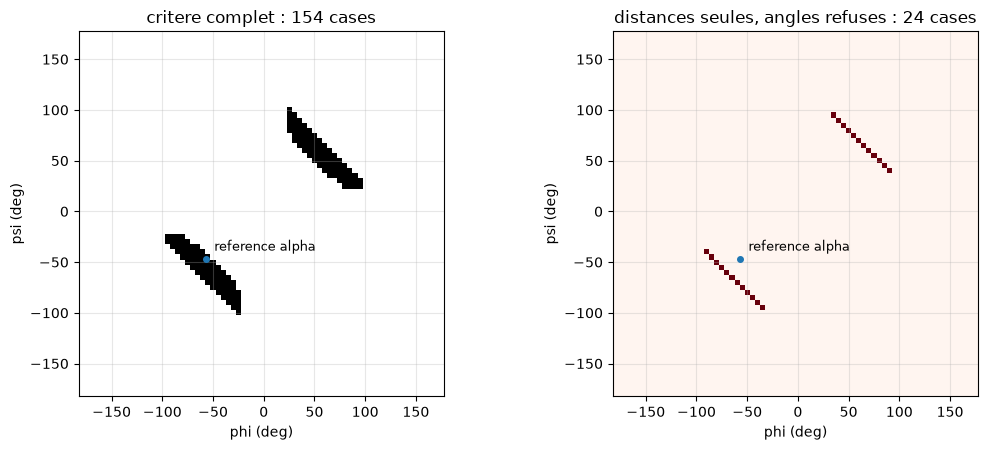

In [11]:
def cartes(pas_liaison=4, angle_ncac=A_N_CA_C, n=12, donneur=6):
    '''Carte (phi, psi) du critere complet et des distances seules, pour un saut donne.'''
    grille = np.arange(-180.0, 180.0, 5.0)
    ok = np.zeros((len(grille), len(grille)), dtype=bool)
    dist = np.zeros_like(ok)
    for j, psi in enumerate(grille):
        for i, phi in enumerate(grille):
            chaine = construire_chaine(np.full(n, phi), np.full(n, psi), angle_ncac=angle_ncac)
            m = critere_liaison(chaine, donneur, donneur - pas_liaison)
            ok[j, i] = m['ok']
            dist[j, i] = m['HO'] < 2.7 and m['NO'] < 3.5
    return grille, ok, dist

def bassins(grille, ok):
    '''Regions connexes de la carte, triees par taille decroissante.'''
    # Connexite par les cotes (structure par defaut) : deux regions qui ne se
    # touchent que par un coin restent deux regions distinctes.
    etiquettes, nb = scipy.ndimage.label(ok)
    sortie = []
    for etiquette in range(1, nb + 1):
        lignes, colonnes = np.nonzero(etiquettes == etiquette)
        sortie.append({
            'taille': len(lignes),
            'phi': float(grille[colonnes].mean()),
            'psi': float(grille[lignes].mean()),
            'lignes': lignes,
            'colonnes': colonnes,
        })
    sortie.sort(key=lambda b: (-b['taille'], b['phi']))
    return sortie

grille, ok, dist = cartes()
regions = bassins(grille, ok)
print(f'quatre conditions : {ok.sum()} cases sur {ok.size} ({100 * ok.mean():.2f} %)')
print(f'distances seules  : {dist.sum()} cases ({100 * dist.mean():.2f} %)')
print(f'cases que les deux conditions d angle retirent : {(dist & ~ok).sum()}')
for b in regions:
    print(f'region de {b["taille"]} cases, barycentre (phi {b["phi"]:.2f}, psi {b["psi"]:.2f}), '
          f'phi {grille[b["colonnes"]].min():.0f}..{grille[b["colonnes"]].max():.0f}, '
          f'psi {grille[b["lignes"]].min():.0f}..{grille[b["lignes"]].max():.0f}')

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.6))
etendue = [grille[0] - 2.5, grille[-1] + 2.5, grille[0] - 2.5, grille[-1] + 2.5]
axes[0].imshow(ok, origin='lower', extent=etendue, cmap='Greys', aspect='equal')
axes[0].set_title(f'critere complet : {ok.sum()} cases')
axes[1].imshow(dist & ~ok, origin='lower', extent=etendue, cmap='Reds', aspect='equal')
axes[1].set_title(f'distances seules, angles refuses : {(dist & ~ok).sum()} cases')
for ax in axes:
    ax.plot(*ALPHA, marker='o', markersize=4, color='tab:blue')
    ax.annotate('reference alpha', ALPHA, textcoords='offset points', xytext=(6, 6), fontsize=9)
    ax.set_xlabel('phi (deg)')
    ax.set_ylabel('psi (deg)')
plt.tight_layout()
plt.show()

### Lecture du résultat

Le critère complet retient **154 cases sur 5184**, soit $2{,}97\,\%$ de la carte, réparties en **deux régions de 77 cases** exactement symétriques, de barycentres $(-56{,}23,\,-57{,}73)$ et $(56{,}23,\,57{,}73)$. Les deux régions sont images miroir l'une de l'autre, et cela ne doit pas surprendre : le critère ne fait intervenir que des distances et des angles non orientés, donc il ne peut pas distinguer une hélice droite de son image.

Les deux conditions de distance seules retiennent 178 cases ; les deux conditions d'angle n'en retirent que **24**. L'essentiel du bassin est donc déjà dessiné par la seule géométrie des distances $H\cdots O$ et $N\cdots O$, et les angles tranchent les cas limites. C'est une information sur le critère, pas sur la protéine : un crible qui ne rejette que $13\,\%$ de ce que les distances acceptent n'est pas très exigeant.

La forme du bassin est une bande diagonale, non un disque : à $\psi = -100°$ la bande n'existe qu'autour de $\varphi = -25°$ ; à $\psi = -50°$ elle court de $\varphi = -75°$ à $-50°$ ; à $\psi = -25°$ elle s'est déplacée jusqu'à $\varphi \approx -95°$ à $-80°$. Dans le critère complet, elle garde au plus six cases de large, et au cœur de la bande $\varphi$ recule d'un pas de grille quand $\psi$ avance d'un pas : c'est la trace d'une hélice, dont les deux angles doivent varier ensemble. Le couple de référence $(-57°,-47°)$ tombe à l'intérieur ; comme la grille est au pas de $5°$, il n'est pas lui-même une case — la case la plus proche est $(-55°,-45°)$.

In [12]:
# Resume du bassin par cinq grandeurs helicoidales, lues comme des INTERVALLES et non comme
# un point : le critere retient une famille d'helices voisines, pas une helice unique. Chaque
# case retenue est reconstruite par la meme fonction que la reference, ce qui garantit que le
# bassin et la reference sont mesures dans les memes unites.
bassin = regions[0]
tableau = []
for ligne, colonne in zip(bassin['lignes'], bassin['colonnes']):
    p = parametres_reguliers(float(grille[colonne]), float(grille[ligne]))
    tableau.append((p['par_tour'], p['pas'], p['rayon'], p['theta_v'], p['tau_v']))
tableau = np.array(tableau)

affiches = ['residus par tour', 'pas axial (A)', 'rayon (A)', 'theta_v (deg)', 'tau_v (deg)']
for nom, colonne in zip(affiches, tableau.T):
    print(f'{nom:18s} {colonne.min():9.4f} .. {colonne.max():9.4f}')

# La reference est affichee sur la meme ligne de format, pour se lire colonne par colonne
# contre les intervalles du bassin.
p_alpha = parametres_reguliers(*ALPHA)
print(f'{"reference alpha":18s} {p_alpha["par_tour"]:9.4f}    {p_alpha["pas"]:9.4f}   {p_alpha["rayon"]:9.4f}   '
      f'{p_alpha["theta_v"]:9.4f}   {p_alpha["tau_v"]:9.4f}')

# De dernieres lectures : la case de grille la plus proche de la reference (le couple de
# reference n'est pas lui-meme une case), le rang de la reference parmi les cases du bassin,
# et l'unanimite du signe des diedres, qui dit si le bassin melange les deux sens d'enroulement.
ligne_proche = int(np.argmin(abs(grille - ALPHA[1])))
colonne_proche = int(np.argmin(abs(grille - ALPHA[0])))
print(f'case la plus proche de la reference : (phi {grille[colonne_proche]:.0f}, psi {grille[ligne_proche]:.0f}), '
      f'retenue {bool(ok[ligne_proche, colonne_proche])}')
rang = int((tableau[:, 0] <= p_alpha['par_tour']).sum())
print(f'rang de la reference en residus par tour : {rang} sur {len(tableau)}')
print(f'les tau_v du bassin sont tous de meme signe : {bool(np.all(tableau[:, 4] > 0) or np.all(tableau[:, 4] < 0))}')

residus par tour      3.5099 ..    4.1289
pas axial (A)         1.0315 ..    1.6532
rayon (A)             2.2102 ..    2.6706
theta_v (deg)        89.7692 ..   98.4728
tau_v (deg)          28.8020 ..   56.6658
reference alpha       3.6033       1.5304      2.2894     90.8928     50.9155
case la plus proche de la reference : (phi -55, psi -45), retenue True
rang de la reference en residus par tour : 8 sur 77
les tau_v du bassin sont tous de meme signe : True


### Lecture du résultat

Les 77 cases du bassin ne sont pas 77 copies d'une même hélice. Les paramètres varient d'un bout à l'autre : de **3,5099 à 4,1289 résidus par tour**, un pas axial de 1,0315 à 1,6532 Å, un rayon de 2,2102 à 2,6706 Å, un $\theta_v$ de 89,77° à 98,47°. Toutes ont en revanche un $\tau_v$ de même signe — de $+28{,}80°$ à $+56{,}67°$ — donc **une seule main** : le bassin ne mélange pas les deux hélices possibles, et son image occupe l'autre région de la carte.

Le point de référence $(-57°,-47°)$ correspond à $3{,}6033$ résidus par tour, un pas de $1{,}53038$ Å et un rayon de $2{,}28944$ Å ; il se classe **8ᵉ sur 77** en résidus par tour, c'est-à-dire près du bout serré du bassin. Une hélice $\alpha$ est donc, dans ce modèle, une hélice plutôt serrée parmi celles que le critère accepte — et non le centre du bassin.

C'est la réponse à la question de la section : la carte ne fait pas un point. Le critère sélectionne une **famille** d'hélices régulières qui diffèrent de plus d'un demi-résidu par tour, et rien dans le critère ne privilégie l'une d'elles. Ce qui privilégie l'hélice $\alpha$ dans une vraie protéine — l'empilement, l'effet hydrophobe, les ponts entre chaînes latérales — n'est pas dans ce carnet, et c'est précisément ce que les feuilles suivantes devront apporter.

### Exercice 1 — la carte change-t-elle quand la liaison saute un résidu de plus ?

Le carnet a fixé le couple testé à $i+4 \to i$, le tour de l'hélice $\alpha$. Que devient la carte pour $i+3 \to i$ et pour $i+5 \to i$ ?

**À faire.** Recalculer la carte pour un saut de 3 et pour un saut de 5, puis comparer au saut de 4 : nombre de cases, nombre de régions, étendue des résidus par tour dans la plus grande région.

**Indice.** `cartes` prend `pas_liaison` en argument ; `bassins` prend la carte obtenue ; `parametres_reguliers` donne les paramètres d'une case.

**Étape 1.** Écrire `analyse_carte(pas_liaison)` qui renvoie le nombre de cases, le nombre de régions et l'étendue des résidus par tour de la plus grande.
**Étape 2.** L'appliquer aux sauts 3, 4 et 5.
**Étape 3.** Conclure : le bassin se déplace-t-il, se rétrécit-il, ou change-t-il de main ?

In [13]:
def analyse_carte(pas_liaison):
    # TODO etudiant : renvoyer le nombre de cases, le nombre de regions et
    # l'etendue des residus par tour dans la plus grande (etape 1)
    return None


# Etape 2 : appliquer aux sauts de 3, 4 et 5, puis comparer
for saut in (3, 4, 5):
    resultat = analyse_carte(saut)
    if resultat is None:
        print(f'saut {saut} : exercice a completer')
    else:
        print(f'saut {saut} : {resultat}')

saut 3 : exercice a completer
saut 4 : exercice a completer
saut 5 : exercice a completer


## 4. La vis de l'hélice et la rotation du groupe peptidique

Une hélice régulière est le lieu d'une **vis** : une rotation d'angle $\kappa$ autour d'un axe, composée d'une translation de pas $d$ le long de ce même axe. Sur les carbones $\alpha$, la vis se mesure sans rien supposer. La rotation rigide qui amène le triplet de liaisons $(b_k, b_{k+1}, b_{k+2})$ sur le triplet suivant est, pour une hélice régulière, **la même pour tous les $k$** : c'est la rotation de la vis. Le carnet exploite cette propriété et non un ajustement d'axe par moments, qui échoue précisément quand le pas approche $100°$ parce que les azimuts se répartissent alors en amas et que la covariance transverse devient très anisotrope.

Penner attache à chaque groupe peptidique un repère mobile dont le troisième axe est le produit vectoriel des deux premiers et dont le plan contient la liaison $C_i-N_{i+1}$ (sa Fig. 2) ; il indexe une liaison hydrogène par la rotation entre les repères du donneur et de l'accepteur. Le carnet construit le même repère et mesure cette rotation.

La question de la section est donc double : la vis mesurée sur les coordonnées est-elle celle que prédit la formule, et la **rotation du repère peptidique** d'un résidu au suivant est-elle cette même vis ?

vis mesuree    : angle +99.907878 deg, pas 1.530383 A, rayon 2.289443 A, 3.6033 residus par tour
vis analytique : angle +99.907878 deg, pas 1.530383 A, rayon 2.289443 A
ecart mesure - analytique : angle +0.0e+00 deg, pas -1.6e-15 A, rayon +4.4e-16 A
axe de la vis : [0.656648 0.46433  0.594316]
dispersion : rotations identiques a 2.3e-15, azimuts a 3.3e-13, pas a 7.8e-15, rayon a 8.4e-15
rotation du groupe 13 vers le groupe 12 (1 pas) : angle 99.9079 deg, det 1.000000000000, |cos| entre axe de rotation et axe de vis 1.00000000
rotation du groupe 13 vers le groupe 9 (4 pas) : angle 39.6315 deg, det 1.000000000000, |cos| entre axe de rotation et axe de vis 1.00000000
controle : kappa = 99.9079 ; 4 kappa ramene dans [0, 180] = 39.6315


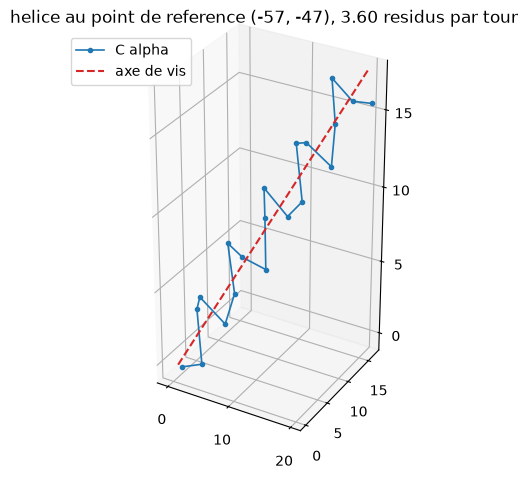

In [14]:
# Deux voies independantes pour la meme vis : la MESURE, qui ajuste une helice sur les atomes
# construits, et la FORMULE analytique, qui ne lit que la longueur d'un pas, l'angle de valence
# et le diedre du squelette. Leur ecart est le controle de la section : il doit etre nul au bruit
# flottant pres, et non seulement petit.
vis = mesurer_vis(chaine_alpha['CA'])
vis_an = vis_analytique(
    float(np.linalg.norm(chaine_alpha['CA'][1] - chaine_alpha['CA'][0])),
    float(angle(chaine_alpha['CA'][0], chaine_alpha['CA'][1], chaine_alpha['CA'][2])),
    float(dihedre(chaine_alpha['CA'][0], chaine_alpha['CA'][1], chaine_alpha['CA'][2], chaine_alpha['CA'][3])),
)
print(f'vis mesuree    : angle {vis["angle"]:+.6f} deg, pas {vis["pas"]:.6f} A, rayon {vis["rayon"]:.6f} A, '
      f'{vis["par_tour"]:.4f} residus par tour')
print(f'vis analytique : angle {vis_an["angle"]:+.6f} deg, pas {vis_an["pas"]:.6f} A, rayon {vis_an["rayon"]:.6f} A')
print(f'ecart mesure - analytique : angle {abs(vis["angle"]) - vis_an["angle"]:+.1e} deg, '
      f'pas {vis["pas"] - vis_an["pas"]:+.1e} A, rayon {vis["rayon"] - vis_an["rayon"]:+.1e} A')
print(f'axe de la vis : {np.round(vis["axe"], 6)}')
print(f'dispersion : rotations identiques a {vis["ecart_rotations"]:.1e}, azimuts a {vis["ecart_azimut"]:.1e}, '
      f'pas a {vis["ecart_pas"]:.1e}, rayon a {vis["ecart_rayon"]:.1e}')

# TROISIEME voie : la rotation qui porte un groupe peptidique sur le suivant. L'axe de la vis est
# d'abord exprime dans le repere local du groupe, pour etre compare a l'axe de cette rotation ;
# on essaie un pas puis quatre pas, pour verifier que la rotation cumulee reste sur le meme axe.
for nombre_pas in (1, 4):
    rot = rotation_groupes(chaine_alpha, 13, 13 - nombre_pas)
    axe_dans_repere = repere_groupe(chaine_alpha, 13).T @ vis['axe']
    print(f'rotation du groupe 13 vers le groupe {13 - nombre_pas} ({nombre_pas} pas) : '
          f'angle {rot["angle"]:.4f} deg, det {np.linalg.det(rot["R"]):.12f}, '
          f'|cos| entre axe de rotation et axe de vis {abs(np.dot(rot["axe"], axe_dans_repere)):.8f}')
# Coherence des deux lectures : l'angle mesure sur quatre pas doit etre celui de la composition
# de quatre rotations d'un pas, ramene dans [0, 180]. Il n'est pas nul : un tour de cette helice
# ne compte pas un nombre entier de residus, ce que cette ligne rend visible.
print(f'controle : kappa = {vis["angle"]:.4f} ; 4 kappa ramene dans [0, 180] = '
      f'{abs(((4.0 * vis["angle"] + 180.0) % 360.0) - 180.0):.4f}')

# La figure porte l'axe de la vis en plus des atomes : c'est lui qui rend visible que la chaine
# tourne autour d'une droite fixe. Il est trace comme la droite qui passe par le pied moyen
# des atomes projetés, allongee au-dela des deux extremites.
fig = plt.figure(figsize=(6.4, 5.2))
ax = fig.add_subplot(projection='3d')
ax.plot(*chaine_alpha['CA'].T, marker='o', markersize=3, linewidth=1.2, label='C alpha')
hauteurs = chaine_alpha['CA'] @ vis['axe']
pied = (chaine_alpha['CA'] - np.outer(hauteurs, vis['axe'])).mean(axis=0)
extremites = pied + np.outer([hauteurs.min() - 0.8, hauteurs.max() + 0.8], vis['axe'])
ax.plot(*extremites.T, linestyle='--', color='tab:red', label='axe de vis')
ax.set_title(f'helice au point de reference ({ALPHA[0]:.0f}, {ALPHA[1]:.0f}), {vis["par_tour"]:.2f} residus par tour')
ax.legend()
ax.set_box_aspect([1, 1, 2])
ax.locator_params(axis='x', nbins=4)
ax.locator_params(axis='y', nbins=4)
ax.locator_params(axis='z', nbins=5)
plt.show()

### Lecture du résultat

Au point de référence, $d = 3{,}824779340040$ Å, $\theta_v = 90{,}8927803075°$ et $\tau_v = +50{,}9154815749°$ donnent une vis d'angle $\kappa = 99{,}9079°$, soit $3{,}6033$ résidus par tour, un pas de $1{,}53038$ Å et un rayon de $2{,}28944$ Å. La vis **mesurée** sur les coordonnées redonne $+99{,}907878°$, un pas de $1{,}530383$ Å et un rayon de $2{,}289443$ Å : l'écart à la formule est nul en angle et de l'ordre de $10^{-15}$ Å sur les longueurs. Les rotations d'un pas au suivant sont identiques à $2{,}3\times10^{-15}$ près et les azimuts à $3{,}3\times10^{-13}$ — l'hélice est régulière, et la vis est exactement la même à chaque pas.

Le résultat de la section est le suivant. La rotation rigide qui amène le repère du groupe peptidique 13 sur celui du groupe 12 vaut $99{,}9079°$, c'est-à-dire $\kappa$ ; sur quatre pas, elle vaut $39{,}6315°$, c'est-à-dire $4\kappa$ ramené dans $[0,180]$. Son axe est confondu avec l'axe de l'hélice : le cosinus entre les deux vaut $1{,}00000000$, et le déterminant de la rotation vaut $1{,}000000000000$, donc c'est bien une rotation et non une réflexion.

Autrement dit : **l'élément de $SO(3)$ que porte une liaison hydrogène le long d'une hélice est la rotation de la vis de cette hélice, autour de son axe.** C'est le contenu géométrique de la construction de la Fig. 2 de Penner, mesuré ici sur un modèle. Le carnet ne reproduit pas sa figure : il ne mesure pas la distribution de ces rotations sur des structures déposées, il mesure ce qu'une seule hélice régulière en donne.

### Contre-témoin : trois cas où la mesure doit se distinguer elle-même

Un contrôle ne vaut que s'il sait échouer. Trois cas sont construits, chacun pour une confusion différente.

**Le miroir.** La chaîne de couples $(-\varphi,-\psi)$ est l'image de la précédente. Le critère doit l'accepter — il ne voit pas les signes —, et la vis doit changer de signe sans changer d'angle de rotation. Si l'angle de rotation distinguait les deux mains, c'est la mesure qui serait mal construite.

**La conformation étendue.** Le couple qui éloigne le plus les extrémités de la chaîne ne doit porter aucune liaison $i+4 \to i$ : si le critère en trouvait une, il confondrait « étiré » et « hélicoïdal ».

**La liaison peptidique tordue.** En imposant $\omega = 160°$ au lieu de $180°$, le groupe peptidique cesse d'être plan. Le critère de liaison, qui ne regarde que des distances et des angles autour de $H$ et $O$, ne doit pas s'en apercevoir ; c'est le contrôle de planéité qui doit le voir. Ce cas mesure la portée exacte du critère, et la limite annoncée à la section 2.

In [15]:
chaine_miroir = construire_chaine(np.full(20, -ALPHA[0]), np.full(20, -ALPHA[1]))
m_miroir = critere_liaison(chaine_miroir, 12, 8)
vis_miroir = mesurer_vis(chaine_miroir['CA'])
rot_miroir = rotation_groupes(chaine_miroir, 13, 9)
print(f'miroir ({-ALPHA[0]:.0f}, {-ALPHA[1]:.0f}) : critere retenu {m_miroir["ok"]} '
      f'(H...O {m_miroir["HO"]:.3f} A, N...O {m_miroir["NO"]:.3f} A)')
print(f'  tau_v {dihedre(chaine_miroir["CA"][0], chaine_miroir["CA"][1], chaine_miroir["CA"][2], chaine_miroir["CA"][3]):+.4f} deg ; '
      f'pas de vis {vis_miroir["angle"]:+.4f} deg ; rotation sur 4 pas {rot_miroir["angle"]:.4f} deg')

# conformation la plus etendue : bout a bout maximal sur une grille grossiere
grille_etendue = np.arange(-180.0, 180.0, 10.0)
bout_a_bout = np.zeros((len(grille_etendue), len(grille_etendue)))
for j, psi in enumerate(grille_etendue):
    for i, phi in enumerate(grille_etendue):
        c = construire_chaine(np.full(10, phi), np.full(10, psi))
        bout_a_bout[j, i] = np.linalg.norm(c['CA'][-1] - c['CA'][0])
j_etend, i_etend = np.unravel_index(np.argmax(bout_a_bout), bout_a_bout.shape)
point_etendu = (float(grille_etendue[i_etend]), float(grille_etendue[j_etend]))
print(f'conformation la plus etendue ({point_etendu[0]:.0f}, {point_etendu[1]:.0f}) : bout a bout '
      f'{bout_a_bout[j_etend, i_etend]:.4f} A sur 9 pas = {bout_a_bout[j_etend, i_etend] / 9.0:.4f} A par residu')
chaine_etendue = construire_chaine(np.full(16, point_etendu[0]), np.full(16, point_etendu[1]))
for saut in (4, -4):
    m = critere_liaison(chaine_etendue, 8, 8 + saut)
    print(f'  donneur 8, accepteur {8 + saut} : retenu {m["ok"]} (H...O {m["HO"]:.3f} A, N...O {m["NO"]:.3f} A)')

# omega = 160 deg : vingt degres de torsion cassent la planarite du groupe peptidique
# tout en laissant le critere reussir, ce qui est precisement le point du contre-temoin.
chaine_tordue = construire_chaine(np.full(16, ALPHA[0]), np.full(16, ALPHA[1]), omegas=np.full(15, 160.0))
pl_tordue = planarite(chaine_tordue)
m_tordue = critere_liaison(chaine_tordue, 12, 8)
print(f'omega = 160 deg : planarite moyenne {pl_tordue.mean():.4f} A, max {pl_tordue.max():.4f} A')
print(f'  critere 12 -> 8 : retenu {m_tordue["ok"]} avec H...O {m_tordue["HO"]:.4f} A, '
      f'N...O {m_tordue["NO"]:.4f} A, N-H...O {m_tordue["NHO"]:.1f} deg')

miroir (57, 47) : critere retenu True (H...O 1.978 A, N...O 2.975 A)
  tau_v -50.9155 deg ; pas de vis -99.9079 deg ; rotation sur 4 pas 39.6315 deg


conformation la plus etendue (-180, -180) : bout a bout 32.8047 A sur 9 pas = 3.6450 A par residu
  donneur 8, accepteur 12 : retenu False (H...O 16.803 A, N...O 16.941 A)
  donneur 8, accepteur 4 : retenu False (H...O 12.343 A, N...O 12.313 A)
omega = 160 deg : planarite moyenne 0.1600 A, max 0.1600 A
  critere 12 -> 8 : retenu True avec H...O 0.4239 A, N...O 1.3744 A, N-H...O 143.6 deg


### Lecture du contre-témoin

Le miroir est accepté par le critère, avec un $N\cdots O$ de $2{,}975$ Å identique au cas direct ; son $\tau_v$ vaut $-50{,}9155°$ et son pas de vis $-99{,}9079°$, tandis que la rotation du groupe peptidique sur quatre pas redonne $39{,}6315°$, **la même valeur**. L'angle de rotation ne distingue donc pas les deux mains : c'est le signe de $\tau_v$, donc le signe de $\kappa$, qui les distingue. Et puisque le critère accepte les deux, le modèle est **achiral** — ce que la carte de la section 3 montrait déjà par ses deux régions miroir, et ce qui veut dire que le modèle **n'explique pas** pourquoi l'hélice $\alpha$ est droite.

La conformation la plus étendue met les extrémités à $3{,}6450$ Å par résidu, et n'ouvre aucune liaison $i+4 \to i$ ni $i-4 \to i$. Le critère ne confond pas étirement et hélice.

La liaison tordue à $\omega = 160°$ fait passer la planéité du groupe peptidique de l'arrondi numérique à $0{,}1600$ Å, et pourtant le critère accepte la liaison, avec $H\cdots O = 0{,}4239$ Å. Un hydrogène à quatre dixièmes d'angström de l'oxygène est un empilement stérique impossible — les rayons de van der Waals de ces deux atomes se comptent en dixièmes de nanomètre — et le critère, qui ne fixe que des bornes supérieures, le laisse passer. C'est la limite annoncée à la section 2, mesurée plutôt que supposée : un critère à quatre conditions doit être accompagné d'un contrôle de planéité et de distance minimale, sans quoi il accepte des conformations physiquement absurdes.

### Exercice 2 — quelle grandeur porte la chiralité ?

Le contre-témoin a montré que l'angle de rotation ne distingue pas les deux mains. Faire l'inventaire complet, sur une chaîne et sur son miroir, des grandeurs que le carnet sait mesurer.

**À faire.** Pour un couple $(\varphi,\psi)$ donné et son image $(-\varphi,-\psi)$, calculer le dièdre des quatre premiers carbones $\alpha$, $\theta_v$, $\tau_v$, $\kappa$, le pas axial, le rayon, et le verdict du critère. Classer ces grandeurs en « invariantes par miroir » et « qui changent de signe ».

**Indice.** Le résultat attendu est un partage net, mais deux pièges attendent. Le **verdict** du critère est invariant, puisqu'il accepte les deux mains : demander si la liaison existe ne répond donc pas à la question. Et $\kappa$ ne porte un signe que parce que l'instrument le lit sur la rotation ; la formule analytique n'en rend que la valeur absolue.

**Étape 1.** Construire les deux chaînes.
**Étape 2.** Mesurer les sept grandeurs sur chacune.
**Étape 3.** Conclure laquelle, seule, distingue les deux mains.

In [16]:
def inventaire_chiral(phi, psi):
    # TODO etudiant : mesurer les sept grandeurs sur la chaine et sur son miroir,
    # puis renvoyer un dictionnaire nom -> (valeur directe, valeur miroir) (etapes 1 a 3)
    return None


inventaire = inventaire_chiral(*ALPHA)
if inventaire is None:
    print('Exercice a completer : aucune mesure pour l instant.')
else:
    for nom, valeurs in inventaire.items():
        print(f'{nom:24s} directe {valeurs[0]:+.4f}   miroir {valeurs[1]:+.4f}')

Exercice a completer : aucune mesure pour l instant.


### Exercice 3 — le bassin survit-il à l'angle de valence déclaré ?

Tous les résultats des sections 3 et 4 reposent sur un angle $N-C_\alpha-C$ déclaré à $109{,}47°$. Un squelette réel n'a pas exactement cette valeur. Que devient la carte si on la porte à $111°$ ?

**À faire.** Recalculer la vis du point de référence, la carte complète, le nombre de cases et l'étendue des résidus par tour du plus grand bassin, pour $109{,}47°$ puis pour $111°$.

**Indice.** `cartes` et `parametres_reguliers` prennent tous deux `angle_ncac` en argument. Comparer les deux cartes, pas seulement leurs totaux : le bassin se déplace-t-il, et de combien ?

**Étape 1.** Écrire `carte_angle(angle_ncac)`.
**Étape 2.** L'appliquer aux deux valeurs.
**Étape 3.** Conclure : le bassin est-il une propriété du critère, ou un artefact d'un paramètre déclaré ?

In [17]:
def carte_angle(angle_ncac):
    # TODO etudiant : renvoyer le nombre de cases retenues et l'etendue des residus
    # par tour de la plus grande region, pour cet angle N-CA-C declare (etapes 1 a 3)
    return None


for angle_declare in (109.47, 111.0):
    resultat = carte_angle(angle_declare)
    if resultat is None:
        print(f'angle declare {angle_declare} deg : exercice a completer')
    else:
        print(f'angle declare {angle_declare} deg : {resultat}')

angle declare 109.47 deg : exercice a completer
angle declare 111.0 deg : exercice a completer


## 5. Statut de ce que le carnet établit

**Mesuré dans ce carnet.**

- Le constructeur redonne ses propres dièdres à la précision de la machine, ses cinq longueurs et ses trois angles de valence exactement, et la planéité du groupe peptidique à l'arrondi numérique.
- Une chaîne à couples $(\varphi,\psi)$ constants est une hélice régulière au sens fort : $d = 3{,}824779340040$ Å, $\theta_v = 90{,}8927803075°$, $\tau_v = +50{,}9154815749°$ le long de toute la chaîne, indépendamment de la graine de la première liaison.
- Le critère à quatre conditions retient la liaison $i+4 \to i$ au point de référence, et refuse l'affectation inverse avec un $N\cdots O$ de $9{,}576$ Å.
- La carte contient 154 cases sur 5184, soit $2{,}97\,\%$, en deux régions miroir de 77 cases ; les conditions d'angle retirent 24 des 178 cases qu'acceptent les distances seules.
- Le bassin est une famille d'hélices régulières de 3,5099 à 4,1289 résidus par tour, d'une seule main, dont le point de référence occupe le rang 8 sur 77.
- La rotation du repère peptidique d'un résidu au suivant vaut $\kappa$ et son axe est l'axe de l'hélice, avec un cosinus de $1{,}00000000$ entre les deux.
- La vis mesurée et la vis analytique coïncident, et la vis portée par le repère est la même transformation.
- Le critère admet un empilement stérique, et seule la planéité le détecte.

**Cité, non redémontré.** Le critère à quatre conditions et ses seuils viennent de DSSP tel que Penner les reprend ; la construction du repère mobile est celle de sa Fig. 2 ; l'existence d'une statistique de ces rotations sur les structures déposées, dont le mode est le tour de l'hélice $\alpha$ idéale, est son résultat — il n'est pas reproduit ici.

**Ouvert.** Pourquoi l'hélice $\alpha$ est droite, ce que ce modèle achiral ne peut pas dire. La distribution réelle des liaisons hydrogène dans des structures déposées, qui demande une base expérimentale et DSSP. Et le repliement lui-même, objet des feuilles suivantes.

### Limites

Le modèle est **achiral** : il accepte une hélice et son image, et ne peut donc pas rendre compte du fait que l'hélice $\alpha$ est droite. Ce n'est pas un défaut d'implémentation, c'est une propriété du critère, montrée par contre-témoin.

Tous les paramètres géométriques sont **déclarés** : longueurs, angles de valence, et le couple de référence lui-même. Le dernier exercice mesure la sensibilité du bassin à l'un d'eux ; les autres n'ont pas été balayés, et une déviation réelle de quelques degrés sur chaque angle déplacerait les frontières du bassin sans le faire disparaître.

Le critère ne fixe que des **bornes supérieures** de distance et des bornes inférieures d'angle : il admet un hydrogène à $0{,}42$ Å de l'oxygène, et c'est la planéité seule qui l'arrête. Une étude sérieuse y ajouterait une borne inférieure et un contrôle de collision.

Enfin, aucune structure expérimentale n'est lue : le carnet mesure ce qu'un modèle prédit, pas ce que les protéines font.

## Références

- Penner, R. C., **Protein Geometry, Function and Mutation**, arXiv:2208.07653v2 [q-bio.BM], 2022, licence CC-BY-NC-ND. <https://arxiv.org/abs/2208.07653>. Copie archivée dans le gisement partagé : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Biology\2022 - Penner - Protein Geometry, Function and Mutation (arXiv 2208.07653v2, CC-BY-NC-ND, OA).pdf`. Sections utilisées : squelette et groupe peptidique, critère à quatre conditions et stipulations de DSSP, repère mobile et Ansatz. Ses figures 3 et 4 ne sont pas reproduites.
- Les quatre conditions du critère reprennent celles de DSSP (Kabsch et Sander) telles que Penner les cite ; le carnet ne lit pas DSSP directement.

## Pour aller plus loin

- La feuille suivante du pli prend le **repliement d'ARN** par l'algorithme de Nussinov, puis par minimisation d'énergie, et le **modèle HP** des protéines sur réseau — les deux autres marches du même pli, celle où l'on cherche une conformation au lieu de la décrire.
- La statistique de Penner — la distribution des rotations sur des structures déposées — demande une base expérimentale filtrée et DSSP : c'est un travail d'une autre nature, hors de ce carnet.
- Les chaînes synthétiques construites ici ne sont pas sans rapport avec les modèles sur réseau de la série [Physique](../../Physique/README.md), section statistique : même idée d'un modèle minimal dont on calcule exactement ce qu'il prédit.
- La sous-série soeur [Dynamiques](../Dynamiques/README.md) traite l'autre versant du vivant : ce qui évolue dans le temps plutôt que ce qui tient dans l'espace.

[↑ Retour au sommaire de la série](../README.md)